# DecisionLab 01 — Comité d’investissement

**Janvier 2021, convention pédagogique.** Vous décidez d’expositions notionnelles à douze marchés immobiliers. Vos données sont de vrais indices Zillow Research, révisés à la date du téléchargement. Il ne s’agit ni de transactions individuelles, ni d’une reconstitution des données connues à l’époque.

**QUID** : où engager du capital sur six mois, avec quels coûts et quel risque ? Une ligne = une métropole et un mois. Indicateur = variation ZHVI à six mois, puis profit simulé. Décision = zones, allocations ou cash.

Ce kit fonctionne hors ligne après installation. Les données de révélation sont détenues séparément par l’enseignant. Ne cherchez pas les résultats historiques sur Internet pendant l’expérience.

Durée du notebook : 65 minutes guidées. **Le code de départ fonctionne sans remplir les TODO** ; ceux-ci demandent d’expliquer, choisir et comparer.

In [2]:
from pathlib import Path
import sys
import json
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas"])
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.json").exists() and (p / "src/modeling.py").exists())
sys.path.insert(0, str(ROOT))
from src.config import load_config
from src.validation import validate_panel
from src.modeling import features, split_training, validation_scores, decision_predictions, fit_predict
from src.decisions import select_allocations, export_strategy
from src.simulation import simulate
C = load_config()
PUBLIC = ROOT / "data/processed/history_public.csv"
panel = validate_panel(pd.read_csv(PUBLIC, parse_dates=["date"]))
assert panel.date.max() <= pd.Timestamp(C["public_cutoff"])
print(panel.shape, panel.region_id.nunique(), panel.date.min(), panel.date.max())
display(panel.head())

(864, 4) 12 2015-01-31 00:00:00 2020-12-31 00:00:00


,region_id,region,date,zhvi
0,394347,"Atlanta, GA",2015-01-31,173942.955176
1,394347,"Atlanta, GA",2015-02-28,174853.818071
2,394347,"Atlanta, GA",2015-03-31,175804.313324
3,394347,"Atlanta, GA",2015-04-30,176865.134295
4,394347,"Atlanta, GA",2015-05-31,178034.638577


## 1. Explorer — 8 min
Tracer trois séries. Vérifier unités, date maximale, nombre de zones et valeurs manquantes.

**TODO** : choisir trois zones ; expliquer pourquoi l’indice ne décrit pas le prix de chaque maison. Attribution : **Data Provided by Zillow Group**.

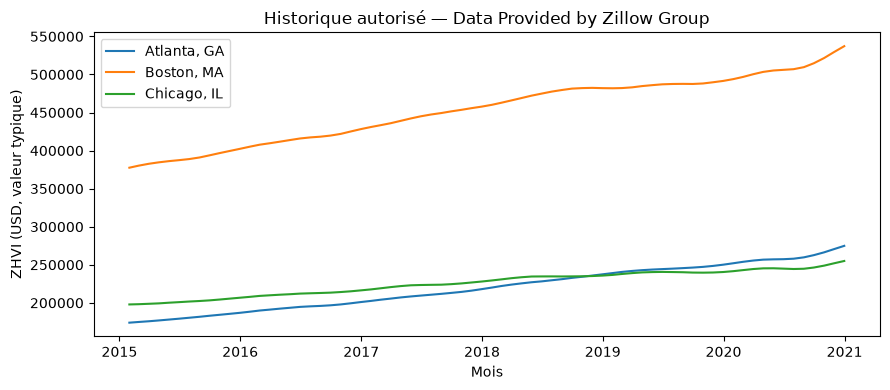

Valeurs absentes : {'region_id': 0, 'region': 0, 'date': 0, 'zhvi': 0}


In [3]:
zones = list(panel.region.unique())[:3]
fig, ax = plt.subplots(figsize=(9, 4))
for name in zones:
    part = panel[panel.region.eq(name)]
    ax.plot(part.date, part.zhvi, label=name)
ax.set(xlabel="Mois", ylabel="ZHVI (USD, valeur typique)", title="Historique autorisé — Data Provided by Zillow Group")
ax.legend()
plt.tight_layout()
plt.show()
print("Valeurs absentes :", panel.isna().sum().to_dict())

## 2. Définir la cible et purger le train — 10 min

`target_pp = 100 × (ZHVI[t+6] / ZHVI[t] − 1)`. Une erreur de 2 signifie **2 points de pourcentage**, pas 2 dollars. Les entrées sont les variations passées à 1, 3, 6 et 12 mois.

Le train ne contient que des cibles entièrement réalisées **avant la première date de validation**. Les dernières lignes sans cible sont conservées pour la décision, jamais utilisées comme labels.

Convention de disponibilité : un mois de délai de publication, non vérifié pour chaque ancienne livraison. Même avec la purge, la série actuelle a été révisée ; ce n’est pas un backtest en données réellement archivées.

**TODO** : expliquer le risque d’un split aléatoire et lire les bornes affichées.

In [4]:
table = features(panel, C["horizon_months"])
train, valid = split_training(table, C)
assert train.target_end.max() < valid.date.min()
print("TRAIN", train.date.min(), train.date.max(), "fin des labels :", train.target_end.max())
print("VALIDATION", valid.date.min(), valid.date.max(), "fin des labels :", valid.target_end.max())
print("Effectifs", len(train), len(valid))
display(table[["region", "date", "return_6m_pp", "target_pp", "target_end"]].head(16))

TRAIN 2016-01-31 00:00:00 2018-06-30 00:00:00 fin des labels : 2018-12-31 00:00:00
VALIDATION 2019-01-31 00:00:00 2019-12-31 00:00:00 fin des labels : 2020-06-30 00:00:00
Effectifs 360 144


,region,date,return_6m_pp,target_pp,target_end
0,"Atlanta, GA",2015-01-31,NaN,3.724157,2015-07-31
1,"Atlanta, GA",2015-02-28,NaN,3.900665,2015-08-31
2,"Atlanta, GA",2015-03-31,NaN,4.102620,2015-09-30
3,"Atlanta, GA",2015-04-30,NaN,4.203907,2015-10-31
4,"Atlanta, GA",2015-05-31,NaN,4.223333,2015-11-30
5,"Atlanta, GA",2015-06-30,NaN,4.304432,2015-12-31
6,"Atlanta, GA",2015-07-31,3.724157,4.415817,2016-01-31
7,"Atlanta, GA",2015-08-31,3.900665,4.528959,2016-02-29
8,"Atlanta, GA",2015-09-30,4.102620,4.427097,2016-03-31
9,"Atlanta, GA",2015-10-31,4.203907,4.374915,2016-04-30


## 3. Baselines et régression — 12 min

Comparer « variation nulle », « dernière variation à six mois » et régression linéaire. Le prétraitement est appris uniquement sur le train.

**TODO** : choisir une méthode sur la validation ; justifier en MAE, RMSE et biais. Aucun score de test futur n’est fourni ici.

In [5]:
scores = validation_scores(table, C)
display(scores.round(3))
MODEL = "linear"  # TODO : zero, momentum ou linear ; choix AVANT révélation
predictions = decision_predictions(panel, MODEL, C)
display(predictions.round(3))

,model,observations,mae_pp,rmse_pp,bias_pp
0,zero,144,2.237,2.617,-2.140
1,momentum,144,1.717,2.264,-0.757
2,linear,144,1.276,1.566,0.719


C:\Users\hp\AppData\Local\Temp\ipykernel_43352\1895257380.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions.round(3))


,region_id,region,date,zhvi,predicted_return_pp
0,394347,"Atlanta, GA",2020-12-31,274874.204,4.047
1,394404,"Boston, MA",2020-12-31,537209.556,3.649
2,394463,"Chicago, IL",2020-12-31,254993.343,2.923
3,394514,"Dallas, TX",2020-12-31,280431.352,3.570
4,394530,"Denver, CO",2020-12-31,466143.645,3.166
5,394856,"Miami, FL",2020-12-31,325594.553,3.544
6,394913,"New York, NY",2020-12-31,529334.502,3.496
7,394976,"Phoenix, AZ",2020-12-31,338724.550,4.525
8,395057,"San Francisco, CA",2020-12-31,972106.334,3.002
9,395078,"Seattle, WA",2020-12-31,570616.640,3.719


## 4. Passer de la prévision à la décision — 15 min

Hypothèses **simulées**, communes à la séance : budget, frais d’achat, frais de vente, portage, limite par zone et cash minimal. La marge de sécurité est un seuil de sélection, **pas un coût ajouté au profit**.

Le code choisit des zones uniquement si leur rendement net prévu dépasse la marge. Il peut ne rien acheter. Les coûts de rénovation et les financements propres à Zillow ne sont pas reconstitués.

**TODO** : tester une marge différente sur la validation, puis fixer la vôtre. Comparer aussi à conserver du cash. Les contraintes communes ne changent pas entre groupes.

In [6]:
economics = dict(C["economics"])
economics["safety_margin_pp"] = C["economics"]["safety_margin_pp"]  # TODO : marge en points
TOP_N = 5
# Validation économique sur douze cohortes mensuelles séparées, budget réinitialisé par cohorte.
# Ces cohortes se chevauchent : ce n’est PAS un portefeuille cumulé ni 12 expériences indépendantes.
validation_economics = []
for origin, cohort in valid.groupby("date"):
    cohort = cohort.copy()
    cohort["predicted_return_pp"] = fit_predict(train, cohort, MODEL, C["horizon_months"])
    positions = select_allocations(cohort, economics, C["horizon_months"], TOP_N)
    actual = cohort[["region_id", "target_pp"]].rename(columns={"target_pp": "actual_return_pp"})
    result, _ = simulate(positions, actual, economics, C["horizon_months"])
    validation_economics.append({"origin": origin, **result})
validation_economics = pd.DataFrame(validation_economics)
display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))
allocations = select_allocations(predictions, economics, C["horizon_months"], TOP_N)
display(pd.DataFrame(allocations, columns=["region_id", "capital_usd"]))
print("Cash volontaire possible. Aucune réalisation future consultée.")

C:\Users\hp\AppData\Local\Temp\ipykernel_43352\3760636952.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))


,origin,capital_engaged_usd,profit_usd,return_on_budget_pct
0,2019-01-31,0.0,0.00,0.00
1,2019-02-28,0.0,0.00,0.00
2,2019-03-31,0.0,0.00,0.00
3,2019-04-30,2000000.0,-38105.38,-0.38
4,2019-05-31,2000000.0,-11672.40,-0.12
5,2019-06-30,0.0,0.00,0.00
6,2019-07-31,0.0,0.00,0.00
7,2019-08-31,0.0,0.00,0.00
8,2019-09-30,0.0,0.00,0.00
9,2019-10-31,0.0,0.00,0.00


,region_id,capital_usd
0,394976,2000000.0


Cash volontaire possible. Aucune réalisation future consultée.


## 5. Geler la stratégie — 8 min

Changer `TEAM` pour votre groupe, vérifier les positions, puis exécuter l’export **une seule fois**. Les fichiers existants ne sont pas remplacés. Remettre le JSON et son empreinte à l’enseignant avant révélation.

**TODO** : dans un fichier `pitch.txt`, écrire la méthode, le motif de la marge et du niveau de cash, un risque et un signal d’arrêt.

L’empreinte détecte les modifications ; seule la collecte externe par l’enseignant établit l’engagement avant révélation.

In [7]:
TEAM = "Groupe_demo"  # TODO : Groupe_1, Groupe_2, Groupe_3 ou Groupe_4
path, sha256 = export_strategy(TEAM, MODEL, allocations, economics, PUBLIC, ROOT / "submissions", C)
print("Fichier à remettre :", path)
print("SHA256 :", sha256)

Fichier à remettre : c:\Users\hp\DecisionLab\usecase\DecisionLab_01_Zillow_Etudiant\submissions\Groupe_demo.json
SHA256 : d2f6aa089456c505b51995e519cd9702d8b7eda93638f3c793334d5566f42b76


## 6. Préparer le conseil d’administration — 12 min

Sans consulter de futur, préparer un pitch de deux minutes :
1. Quelle méthode et quelle erreur de validation ?
2. Combien investir et pourquoi garder du cash ?
3. Quel risque les indices ne représentent-ils pas ?
4. Qu’est-ce qui pourrait invalider votre décision ?

L’enseignant révélera ensuite les indices futurs et fera tourner le moteur privé. Vous interpréterez le profit, les pertes, l’exposition, les scénarios de stress et la différence avec les stratégies naïves. Une bonne MAE ne garantit ni profit ni robustesse.